# Player Archetype Clustering
Goal for this notebook: cluster players into tactical archetypes using the previous in depth statsbomb data.

Notes: 
* The original plan to use FBref stats is no longer viable due to them no longer having access to Opta's advanced passing stats. This means that they would have far less data to be able to cluster into specific archetypes.
* I decided to use the statsbomb api since it is more comprehensive than the current state of FBref.
* The downside to using statsbomb is that they have less leagues and the data is outdated (2015-2016 season) however I still believe this will showcase how effective clustering can be for a player recruitment stand point.

### Setup and data loading

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

from src.player_clustering import find_similar_players
    
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# Original 3 leagues
all_events = pd.read_parquet('../data/raw/statsbomb_events_all.parquet')
match_list = pd.read_parquet('../data/raw/statsbomb_match_list.parquet')

# Ligue 1, pulled separately for this notebook
ligue1_events = pd.read_parquet('../data/raw/statsbomb_ligue1_events.parquet')
ligue1_matches = pd.read_parquet('../data/raw/statsbomb_ligue1_matches.parquet')

# Combine into one 4-league dataset for clustering only
cluster_events = pd.concat([all_events, ligue1_events], ignore_index=True)
cluster_matches = pd.concat([match_list, ligue1_matches[['match_id','home_team','away_team','home_score','away_score','match_date','league']]], ignore_index=True)

print(cluster_events.shape, cluster_matches.shape)
print(cluster_events['league'].value_counts())

(5321459, 121) (1517, 7)
league
Ligue 1           1358593
Serie A           1353739
Premier League    1313773
La Liga           1295354
Name: count, dtype: int64


### Data Analysis
Check out the dataset more in depth since we previously used the statsbomb data set for a different use case in the past. Will need to extract the player data since this is not done for us like in FBref.

In [3]:
# Determine how to extract the starting lineup data
starting_xi_sample = cluster_events[cluster_events['type'] == 'Starting XI'].iloc[0]
print(starting_xi_sample[['type', 'team', 'player', 'tactics']])

type                                             Starting XI
team                                             Real Madrid
player                                                  None
tactics    {'formation': 433.0, 'lineup': [{'jersey_numbe...
Name: 0, dtype: object


In [4]:
# Checkout what is actually in the player dictionary
sample_lineup = cluster_events[cluster_events['type'] == 'Starting XI'].iloc[0]['tactics']['lineup']
print(len(sample_lineup))
sample_lineup[0]

11


{'jersey_number': 1,
 'player': {'id': 5597, 'name': 'Keylor Navas Gamboa'},
 'position': {'id': 1, 'name': 'Goalkeeper'}}

In [5]:
# Create a function to extract the starting lineups from the player dictionaries:
def extract_starting_lineups(events_df):
    starting_xi_events = events_df[events_df['type'] == 'Starting XI']
    
    records = []
    for _, row in starting_xi_events.iterrows():
        for player_entry in row['tactics']['lineup']:
            records.append({
                'match_id': row['match_id'],
                'team': row['team'],
                'player': player_entry['player']['name'],
                'player_id': player_entry['player']['id'],
                'position': player_entry['position']['name'],
            })
    
    return pd.DataFrame(records)

starting_lineups = extract_starting_lineups(cluster_events)
print(starting_lineups.shape)
starting_lineups.head()

(33374, 5)


,match_id,team,player,player_id,position
0,3825739,Real Madrid,Keylor Navas Gamboa,5597,Goalkeeper
1,3825739,Real Madrid,Daniel Carvajal Ramos,5721,Right Back
2,3825739,Real Madrid,Kléper Laveran Lima Ferreira,20016,Right Center Back
3,3825739,Real Madrid,Raphaël Varane,5485,Left Center Back
4,3825739,Real Madrid,Marcelo Vieira da Silva Júnior,5552,Left Back


In [6]:
# Add in total seconds like notebook 3 and then add substitution logic to see who started and who substituted
cluster_events['total_seconds'] = cluster_events['minute'] * 60 + cluster_events['second']

substitution_events = cluster_events[cluster_events['type'] == 'Substitution'][
    ['match_id', 'team', 'player', 'player_id', 'total_seconds', 'substitution_replacement', 'substitution_replacement_id']
].copy()

print(substitution_events.shape)
substitution_events.head()

(8722, 7)


,match_id,team,player,player_id,total_seconds,substitution_replacement,substitution_replacement_id
3938,3825739,Sporting Gijón,Alen Halilović,6926.0,2700,Daniel Arnaud N''Di\t,40822.0
3939,3825739,Real Madrid,Gareth Frank Bale,6399.0,2700,Jesé Rodríguez Ruiz,3990.0
3940,3825739,Real Madrid,Francisco Román Alarcón Suárez,4926.0,3597,James David Rodríguez Rubio,5695.0
3941,3825739,Sporting Gijón,Sergio Álvarez Díaz,13107.0,3621,Rachid Aït-Atmane,27526.0
3942,3825739,Real Madrid,Karim Benzema,19677.0,3895,Mateo Kovačić,5456.0


In [7]:
# Checkout the potential weird names such as Daniel Arnaud N"di\t that we see
weird_names = substitution_events[substitution_events['substitution_replacement'].str.contains(r'[\t\n]', na=False, regex=True)]
print(len(weird_names))
weird_names[['player', 'substitution_replacement']]

5


,player,substitution_replacement
3938,Alen Halilović,Daniel Arnaud N''Di\t
97120,Carlos Carmona Bonet,Daniel Arnaud N''Di\t
148536,Jonathan Rodríguez Menéndez,Daniel Arnaud N''Di\t
164698,Pablo Pérez Rodríguez,Daniel Arnaud N''Di\t
268246,Ognjen Vranješ,Daniel Arnaud N''Di\t


In [8]:
# Isolated fix for one player
for col in ['player', 'substitution_replacement']:
    substitution_events[col] = substitution_events[col].str.strip()

starting_lineups['player'] = starting_lineups['player'].str.strip()

# Confirm it's cleaned
substitution_events[substitution_events['substitution_replacement'].str.contains('N\'\'Di', na=False)][['player', 'substitution_replacement']]

,player,substitution_replacement
3938,Alen Halilović,Daniel Arnaud N''Di
97120,Carlos Carmona Bonet,Daniel Arnaud N''Di
148536,Jonathan Rodríguez Menéndez,Daniel Arnaud N''Di
164698,Pablo Pérez Rodríguez,Daniel Arnaud N''Di
268246,Ognjen Vranješ,Daniel Arnaud N''Di
3967046,Matthieu Saunier,Mahamadou Bamba N''Diaye
4231104,Jérôme Roussillon,Mamadou N''Diaye
4592912,Jonas Martin,Mamadou N''Diaye
5005465,Jérôme Roussillon,Mamadou N''Diaye
5060770,Jérôme Roussillon,Mamadou N''Diaye


### Build actual minutes played calculation


In [9]:
#Get match duration (reusing previous notebooks logic)
match_durations = cluster_events.groupby('match_id')['total_seconds'].max().reset_index()
match_durations.columns = ['match_id', 'match_end_seconds']

In [10]:
# get minutes for starters that were never subbed off
subbed_off_ids = set(zip(substitution_events['match_id'], substitution_events['player_id']))

starters = starting_lineups.merge(match_durations, on='match_id')
starters['was_subbed_off'] = starters.apply(lambda r: (r['match_id'], r['player_id']) in subbed_off_ids, axis=1)

full_match_starters = starters[~starters['was_subbed_off']].copy()
full_match_starters['minutes_played'] = full_match_starters['match_end_seconds'] / 60

In [11]:
# get minutes for starters who were subbed off
subbed_off_starters = starters[starters['was_subbed_off']].merge(
    substitution_events[['match_id', 'player_id', 'total_seconds']],
    on=['match_id', 'player_id']
)
subbed_off_starters['minutes_played'] = subbed_off_starters['total_seconds'] / 60

In [12]:
# get minutes for substitutes that came on
subs_coming_on = substitution_events.merge(match_durations, on='match_id')
subs_coming_on['minutes_played'] = (subs_coming_on['match_end_seconds'] - subs_coming_on['total_seconds']) / 60
subs_coming_on_clean = subs_coming_on[['match_id', 'team', 'substitution_replacement', 'substitution_replacement_id', 'minutes_played']].rename(
    columns={'substitution_replacement': 'player', 'substitution_replacement_id': 'player_id'}
)

In [13]:
# Combine all into one player-match minutes table
player_minutes = pd.concat([
    full_match_starters[['match_id', 'team', 'player', 'player_id', 'position', 'minutes_played']],
    subbed_off_starters[['match_id', 'team', 'player', 'player_id', 'position', 'minutes_played']],
    subs_coming_on_clean
], ignore_index=True)

print(player_minutes.shape)
player_minutes['minutes_played'].describe()

(42096, 6)


count    42096.000000
mean        74.403776
std         28.636524
min          0.333333
25%         60.066667
50%         92.983333
75%         94.033333
max        101.183333
Name: minutes_played, dtype: float64

In [14]:
# Aggregate to season totals per player across all their matches
player_season_minutes = player_minutes.groupby(['player', 'player_id']).agg(
    total_minutes=('minutes_played', 'sum'),
    matches_played=('match_id', 'nunique'),
    position=('position', 'first')
).reset_index()

print(player_season_minutes.shape)
player_season_minutes.sort_values('total_minutes', ascending=False).head(10)

(2185, 5)


,player,player_id,total_minutes,matches_played,position
1168,Kasper Schmeichel,3815.0,3594.016667,38,Goalkeeper
2085,Wes Morgan,3813.0,3594.016667,38,Right Center Back
1910,Simon Francis,3608.0,3591.566667,38,Right Center Back
168,Andrew Surman,3344.0,3591.566667,38,Center Defensive Midfield
2011,Toby Alderweireld,20005.0,3569.183333,38,Right Center Back
1619,Orestis Karnezis,3742.0,3568.266667,38,Goalkeeper
1551,Nampalys Mendy,4506.0,3556.116667,38,Center Defensive Midfield
835,Heurelho da Silva Gomes,3522.0,3554.150000,38,Goalkeeper
395,Craig Dawson,3523.0,3548.666667,38,Right Back
1828,Rémy Vercoutre,2963.0,3547.150000,38,Goalkeeper


In [15]:
# Check if there are any players that do not have a position from starting lineup
print(player_season_minutes['position'].isna().sum())

181


In [16]:
# Check if the missing players actually played
missing_position_players = player_season_minutes[player_season_minutes['position'].isna()]
print(missing_position_players['matches_played'].describe())

count    181.000000
mean       2.558011
std        2.694275
min        1.000000
25%        1.000000
50%        1.000000
75%        3.000000
max       20.000000
Name: matches_played, dtype: float64


In [17]:
player_positions_from_events = cluster_events[cluster_events['position'].notna()][['player', 'position']].drop_duplicates(subset='player')

player_season_minutes = player_season_minutes.merge(
    player_positions_from_events, on='player', how='left', suffixes=('', '_from_events')
)
player_season_minutes['position'] = player_season_minutes['position'].fillna(player_season_minutes['position_from_events'])
player_season_minutes = player_season_minutes.drop(columns='position_from_events')

print(player_season_minutes['position'].isna().sum())

5


In [18]:
# Look at the final 5 players before moving on
still_missing = player_season_minutes[player_season_minutes['position'].isna()]
print(still_missing[['player', 'total_minutes', 'matches_played']])

                       player  total_minutes  matches_played
156            Andrea Favilli       1.950000               1
869    Imanol Corral Matellán       0.666667               1
924                James Weir       0.916667               1
1147  Jérémie Porsan-Clemente       2.466667               1
2110              Yakou Meïté       2.383333               1


In [19]:
# Drop the final 5 players based on minutes played they probably never did anything in the gamnes
player_season_minutes = player_season_minutes.dropna(subset=['position'])
print(player_season_minutes.shape)

(2180, 5)


## Per 90 minutes stats

### Attacking

In [20]:
# Similar to notebook 3 check top scorers
player_shots = cluster_events[cluster_events['type'] == 'Shot'].groupby('player').agg(
    goals=('shot_outcome', lambda x: (x == 'Goal').sum()),
    shots=('shot_outcome', 'count'),
    total_xg=('shot_statsbomb_xg', 'sum'),
).reset_index()

print(player_shots.shape)
player_shots.sort_values('goals', ascending=False).head(10)

(1806, 4)


,player,goals,shots,total_xg
1073,Luis Alberto Suárez Díaz,40,139,27.648656
1775,Zlatan Ibrahimović,36,148,22.698488
658,Gonzalo Gerardo Higuaín,36,182,25.025725
337,Cristiano Ronaldo dos Santos Aveiro,35,228,31.968426
1032,Lionel Andrés Messi Cuccittini,26,158,21.263604
684,Harry Kane,25,158,21.635491
765,Jamie Vardy,24,118,22.298685
965,Karim Benzema,24,98,17.413095
1567,Sergio Leonel Agüero del Castillo,24,118,17.673074
1294,Neymar da Silva Santos Junior,24,123,20.472623


In [21]:
# Check assists
player_assists = cluster_events[
    (cluster_events['type'] == 'Pass') & (cluster_events['pass_goal_assist'] == True)
].groupby('player').size().reset_index(name='assists')

print(player_assists.shape)
player_assists.sort_values('assists', ascending=False).head(10)

(1004, 2)


,player,assists
671,Mesut Özil,19
989,Ángel Fabián Di María Hernández,17
568,Lionel Andrés Messi Cuccittini,15
595,Luis Alberto Suárez Díaz,15
480,Jorge Resurrección Merodio,14
981,Zlatan Ibrahimović,13
249,Dimitri Payet,12
716,Neymar da Silva Santos Junior,12
172,Christian Dannemann Eriksen,12
825,Ryad Boudebouz,11


In [22]:
# Confirm that pass_goal_assist == True
cluster_events['pass_goal_assist'].value_counts(dropna=False)

pass_goal_assist
None    5318863
True       2596
Name: count, dtype: int64

In [23]:
# Combine into one attacking stats table
attacking_stats = player_shots.merge(player_assists, on='player', how='outer')
attacking_stats[['goals', 'shots', 'total_xg', 'assists']] = attacking_stats[['goals', 'shots', 'total_xg', 'assists']].fillna(0)

print(attacking_stats.shape)
attacking_stats.head()

(1818, 5)


,player,goals,shots,total_xg,assists
0,Aaron Cresswell,2.0,27.0,0.800292,4.0
1,Aaron Lennon,5.0,18.0,1.952729,0.0
2,Aaron Ramsey,5.0,67.0,7.372339,4.0
3,Abdelaziz Barrada,1.0,26.0,3.630392,6.0
4,Abdelhamid El Kaoutari,1.0,3.0,0.295646,0.0


In [24]:
# Validation check
attacking_stats.sort_values('goals', ascending=False).head(15)

,player,goals,shots,total_xg,assists
1082,Luis Alberto Suárez Díaz,40.0,139.0,27.648656,15.0
1787,Zlatan Ibrahimović,36.0,148.0,22.698488,13.0
661,Gonzalo Gerardo Higuaín,36.0,182.0,25.025725,2.0
339,Cristiano Ronaldo dos Santos Aveiro,35.0,228.0,31.968426,10.0
1040,Lionel Andrés Messi Cuccittini,26.0,158.0,21.263604,15.0
687,Harry Kane,25.0,158.0,21.635491,1.0
972,Karim Benzema,24.0,98.0,17.413095,5.0
1304,Neymar da Silva Santos Junior,24.0,123.0,20.472623,12.0
770,Jamie Vardy,24.0,118.0,22.298685,5.0
1577,Sergio Leonel Agüero del Castillo,24.0,118.0,17.673074,2.0


### Passing

In [25]:
# Look at the actual location data to confirm coordinate data
sample_pass = cluster_events[cluster_events['type'] == 'Pass'].iloc[0]
print(sample_pass[['location', 'pass_end_location']])

location             [61.0, 40.1]
pass_end_location    [59.3, 42.3]
Name: 6, dtype: object


In [26]:
# Verify pitch dimesnsion and direction
locations = cluster_events['location'].dropna()
xs = locations.apply(lambda loc: loc[0])
ys = locations.apply(lambda loc: loc[1])
print(xs.min(), xs.max())
print(ys.min(), ys.max())

0.1 120.9
0.1 80.4


In [27]:
# Confirm on an real example
sample_team_period1 = cluster_events[(cluster_events['match_id'] == 3825739) & (cluster_events['team'] == 'Real Madrid') & (cluster_events['period'] == 1) & (cluster_events['type'] == 'Pass')]
sample_team_period2 = cluster_events[(cluster_events['match_id'] == 3825739) & (cluster_events['team'] == 'Real Madrid') & (cluster_events['period'] == 2) & (cluster_events['type'] == 'Pass')]

print(sample_team_period1['location'].apply(lambda l: l[0]).describe())
print(sample_team_period2['location'].apply(lambda l: l[0]).describe())

count    401.000000
mean      60.213965
std       24.739400
min        4.600000
25%       42.200000
50%       59.500000
75%       78.100000
max      120.000000
Name: location, dtype: float64
count    385.000000
mean      63.048052
std       22.933893
min        6.200000
25%       49.200000
50%       62.900000
75%       75.600000
max      120.000000
Name: location, dtype: float64


In [28]:
# Explore shots to confirm if statsbomb flips the field or always has the team attacking towards 120
sample_shots_p1 = cluster_events[(cluster_events['match_id'] == 3825739) & (cluster_events['team'] == 'Real Madrid') & (cluster_events['period'] == 1) & (cluster_events['type'] == 'Shot')]
sample_shots_p2 = cluster_events[(cluster_events['match_id'] == 3825739) & (cluster_events['team'] == 'Real Madrid') & (cluster_events['period'] == 2) & (cluster_events['type'] == 'Shot')]

print(sample_shots_p1['location'].apply(lambda l: l[0]).describe())
print(sample_shots_p2['location'].apply(lambda l: l[0]).describe())

count     12.000000
mean     105.983333
std        9.135031
min       86.300000
25%      103.250000
50%      109.200000
75%      110.925000
max      116.800000
Name: location, dtype: float64
count      5.000000
mean     105.740000
std        7.710577
min       97.300000
25%       97.400000
50%      110.000000
75%      111.500000
max      112.500000
Name: location, dtype: float64


Statsbomb normalizes attacking direction which means everyone is attacking towards x= 120 this will help us to find progressive passing and help with possesion stats.

In [29]:
# Create a function to define progressive passes and building the calculation
def distance_to_goal(x):
    return 120 - x

def compute_progressive(df, end_location_col):
    df = df.dropna(subset=['location', end_location_col]).copy()
    start_x = df['location'].apply(lambda l: l[0])
    end_x = df[end_location_col].apply(lambda l: l[0])

    distance_gained = end_x - start_x

    # Standard zone-based thresholds (yards of progress required):
    # own half (start_x < 60): needs 30+ yards forward
    # opponent's half (start_x >= 60): needs 15+ yards forward
    # ending inside the box (end_x >= 102, box starts at x=102 in StatsBomb's 120-unit pitch): any forward progress counts
    threshold = np.where(start_x < 60, 30, 15)
    ends_in_box = end_x >= 102

    df['is_progressive'] = (distance_gained >= threshold) | (ends_in_box & (distance_gained > 0))
    return df

progressive_passes = compute_progressive(cluster_events[cluster_events['type'] == 'Pass'], 'pass_end_location')
progressive_carries = compute_progressive(cluster_events[cluster_events['type'] == 'Carry'], 'carry_end_location')

print(progressive_passes['is_progressive'].sum(), len(progressive_passes))
print(progressive_carries['is_progressive'].sum(), len(progressive_carries))

305376 1481813
87660 1117196


In [30]:
progressive_passes[progressive_passes['is_progressive']][['player', 'location', 'pass_end_location']].sample(5)

,player,location,pass_end_location
3577160,Danilo Soddimo,"[74.9, 5.1]","[105.1, 14.3]"
2814853,Mário Rui Silva Duarte,"[106.9, 0.1]","[113.9, 10.8]"
4017376,Benoît Guy Robert Costil,"[28.9, 49.1]","[79.8, 19.5]"
2317673,Fernando Luiz Rosa,"[42.7, 27.8]","[76.1, 6.8]"
2480746,Àngel Rangel Zaragoza,"[102.6, 65.0]","[113.5, 32.0]"


In [31]:
# Verify box boundary
box_shots = cluster_events[(cluster_events['type'] == 'Shot')]['location'].apply(lambda l: l[0])
print(box_shots.describe())

count    37888.000000
mean       103.209269
std          8.801007
min         35.400000
25%         96.700000
50%        104.500000
75%        110.200000
max        120.200000
Name: location, dtype: float64


In [32]:
# Verify other kinds of passes not just those into the box:
# Recompute the two conditions separately so we can see which one is actually firing
start_x_p = progressive_passes['location'].apply(lambda l: l[0])
end_x_p = progressive_passes['pass_end_location'].apply(lambda l: l[0])
distance_gained_p = end_x_p - start_x_p
threshold_p = np.where(start_x_p < 60, 30, 15)
ends_in_box_p = end_x_p >= 102

met_distance_rule = distance_gained_p >= threshold_p
met_box_rule_only = ends_in_box_p & (distance_gained_p > 0) & (~met_distance_rule)

print("Total progressive:", (met_distance_rule | met_box_rule_only).sum())
print("Met distance threshold:", met_distance_rule.sum())
print("Met ONLY the box-entry rule (didn't meet distance threshold):", met_box_rule_only.sum())

Total progressive: 305376
Met distance threshold: 242605
Met ONLY the box-entry rule (didn't meet distance threshold): 62771


In [33]:
# Aggregate per player
progressive_passes_per_player = progressive_passes[progressive_passes['is_progressive']].groupby('player').size().reset_index(name='progressive_passes')
progressive_carries_per_player = progressive_carries[progressive_carries['is_progressive']].groupby('player').size().reset_index(name='progressive_carries')

print(progressive_passes_per_player.shape, progressive_carries_per_player.shape)
progressive_passes_per_player.sort_values('progressive_passes', ascending=False).head(10)

(2122, 2) (1881, 2)


,player,progressive_passes
1134,Kasper Schmeichel,1051
777,Gorka Iraizoz Moreno,936
228,Asier Riesgo Unamuno,916
191,Antonio Adán Garrido,894
816,Heurelho da Silva Gomes,888
1779,Rémy Vercoutre,868
377,Clément Maury,867
561,Emiliano Viviano,850
931,Jean-Louis Leca,839
257,Benjamin Lecomte,814


In [34]:
# Checkout Craid Dawson as he is a defender in a rather attacking player heavy list
cluster_events[cluster_events['player'] == 'Craig Dawson']['position'].value_counts()

position
Right Back           4401
Right Center Back     162
Left Back              92
Left Center Back       47
Right Midfield         34
Name: count, dtype: int64

In [35]:
cluster_events[cluster_events['player'] == 'Craig Dawson']['team'].unique()

array(['West Bromwich Albion'], dtype=object)

### Pressing Intensity/Defensive actions

In [36]:
# aggregate pressing intensity
player_pressure = cluster_events[cluster_events['type'] == 'Pressure'].groupby('player').size().reset_index(name='pressures')

print(player_pressure.shape)
player_pressure.sort_values('pressures', ascending=False).head(10)

(2101, 2)


,player,pressures
1335,Marten de Roon,1108
1973,Vincent Koziello,1058
824,Idrissa Gana Gueye,1001
670,Franco Damián Vázquez,960
785,Gélson da Conceição Tavares Fernandes,942
1204,Lorenzo Lollo,939
918,Jean-Daniel Akpa Akpro,894
1609,Pedro Mosquera Parada,887
1481,N''Golo Kanté,872
935,Jessy Pi,859


In [37]:
# Aggregate defensive actions: volume (counts) and quality (success rates) where applicable.
# Tackle% and aerial% require a minimum-attempts floor to avoid small-sample noise
# (e.g. a player with 2 attempts and 2 wins showing a meaningless "100%" rate).
MIN_TACKLE_ATTEMPTS = 20
MIN_AERIAL_ATTEMPTS = 20

tackle_events = cluster_events[(cluster_events['type'] == 'Duel') & (cluster_events['duel_type'] == 'Tackle')]
player_tackles_won = tackle_events[tackle_events['duel_outcome'].isin(['Won', 'Success In Play', 'Success Out'])].groupby('player').size().reset_index(name='tackles_won')
tackle_totals = tackle_events.groupby('player').size().reset_index(name='tackle_attempts')

player_tackle_stats = player_tackles_won.merge(tackle_totals, on='player', how='outer').fillna(0)
player_tackle_stats['tackle_pct'] = player_tackle_stats['tackles_won'] / player_tackle_stats['tackle_attempts'].replace(0, np.nan)
player_tackle_stats.loc[player_tackle_stats['tackle_attempts'] < MIN_TACKLE_ATTEMPTS, 'tackle_pct'] = np.nan

# Aerial wins are recorded as flags on the action taken after winning (pass/clearance/shot/miscontrol),
# not as their own Duel event -- only aerial LOSSES appear as a Duel with duel_type == 'Aerial Lost'.
aerial_won_events = pd.concat([
    cluster_events[cluster_events['pass_aerial_won'] == True][['player']],
    cluster_events[cluster_events['clearance_aerial_won'] == True][['player']],
    cluster_events[cluster_events['shot_aerial_won'] == True][['player']],
    cluster_events[cluster_events['miscontrol_aerial_won'] == True][['player']],
], ignore_index=True)
player_aerials_won = aerial_won_events.groupby('player').size().reset_index(name='aerials_won')

aerial_lost_events = cluster_events[(cluster_events['type'] == 'Duel') & (cluster_events['duel_type'] == 'Aerial Lost')]
player_aerials_lost = aerial_lost_events.groupby('player').size().reset_index(name='aerials_lost')

player_aerial_stats = player_aerials_won.merge(player_aerials_lost, on='player', how='outer').fillna(0)
player_aerial_stats['aerial_attempts'] = player_aerial_stats['aerials_won'] + player_aerial_stats['aerials_lost']
player_aerial_stats['aerial_pct'] = player_aerial_stats['aerials_won'] / player_aerial_stats['aerial_attempts'].replace(0, np.nan)
player_aerial_stats.loc[player_aerial_stats['aerial_attempts'] < MIN_AERIAL_ATTEMPTS, 'aerial_pct'] = np.nan

# Interceptions and clearances have no "failed attempt" event type to compare against --
# the event IS the successful outcome by definition, so only a volume count is meaningful here.
player_interceptions = cluster_events[cluster_events['type'] == 'Interception'].groupby('player').size().reset_index(name='interceptions')
player_clearances = cluster_events[cluster_events['type'] == 'Clearance'].groupby('player').size().reset_index(name='clearances')

print(player_tackle_stats.shape, player_aerial_stats.shape, player_interceptions.shape, player_clearances.shape)
player_tackle_stats.sort_values('tackles_won', ascending=False).head(10)

(1892, 4) (1938, 5) (1811, 2) (1888, 2)


,player,tackles_won,tackle_attempts,tackle_pct
741,Idrissa Gana Gueye,100.0,153,0.653595
1340,N''Golo Kanté,97.0,157,0.617834
1204,Marten de Roon,94.0,135,0.696296
1459,Pedro Mosquera Parada,92.0,130,0.707692
572,Filipe Luís Kasmirski,83.0,123,0.674797
823,Jean-Daniel Akpa Akpro,83.0,132,0.628788
684,Gonzalo Escalante,80.0,118,0.677966
1331,Mousa Sidi Yaya Dembélé,80.0,107,0.747664
708,Gélson da Conceição Tavares Fernandes,78.0,129,0.604651
460,Djibril Sidibé,77.0,138,0.557971


In [38]:
player_aerial_stats.sort_values('aerial_attempts', ascending=False).head(10)

,player,aerials_won,aerials_lost,aerial_attempts,aerial_pct
1793,Troy Deeney,304.0,305.0,609.0,0.499179
1676,Sergio Enrich Ametller,193.0,223.0,416.0,0.463942
1612,Rudy Gestede,254.0,142.0,396.0,0.641414
156,Andy Delort,179.0,210.0,389.0,0.460154
382,Daniel Ciofani,176.0,204.0,380.0,0.463158
977,José Salomón Rondón Giménez,141.0,227.0,368.0,0.383152
70,Aleksandar Mitrović,134.0,211.0,345.0,0.388406
189,Aritz Aduriz Zubeldia,194.0,147.0,341.0,0.568915
319,Cheikh N''Doye,230.0,104.0,334.0,0.688623
542,Evaeverson Lemos da Silva Brandão,145.0,180.0,325.0,0.446154


In [39]:
player_interceptions.sort_values('interceptions', ascending=False).head(10)

,player,interceptions
1078,Luis Hernández Rodríguez,131
114,Ander Capa Rodríguez,107
1278,N''Golo Kanté,105
186,Asier Illarramendi Andonegi,103
838,Jonathan Castro Otto,93
1767,Yohan Cabaye,89
555,Filipe Luís Kasmirski,88
683,Hamari Traoré,85
1783,Zouhair Feddal,85
1582,Sidnei Rechel da Silva Júnior,85


In [40]:
player_clearances.sort_values('clearances', ascending=False).head(10)

,player,clearances
193,Ashley Williams,324
1523,Robert Huth,312
1782,Virgil van Dijk,292
297,Chancel Mbemba Mangulu,285
633,Gareth McAuley,262
1739,Toby Alderweireld,258
1679,Steve Cook,253
1806,Wes Morgan,244
316,Chris Smalling,242
662,Giancarlo González Castro,237


In [41]:
# New Aggregations I decided to add after trying clustering
# Shot location -- average distance from goal, to separate box-based poachers from deeper-operating forwards
shots_with_location = cluster_events[cluster_events['type'] == 'Shot'].dropna(subset=['location']).copy()
shots_with_location['shot_x'] = shots_with_location['location'].apply(lambda l: l[0])
shots_with_location['distance_from_goal'] = 120 - shots_with_location['shot_x']
player_avg_shot_distance = shots_with_location.groupby('player')['distance_from_goal'].mean().reset_index(name='avg_shot_distance')

# Shot-assists -- passes leading to any shot, not just goals (far larger, less luck-dependent creativity signal than goal-assists)
player_shot_assists = cluster_events[cluster_events['pass_shot_assist'] == True].groupby('player').size().reset_index(name='shot_assists')

# Through balls -- a specific, high-value creative pass type
player_through_balls = cluster_events[cluster_events['pass_through_ball'] == True].groupby('player').size().reset_index(name='through_balls')

# Dribbles -- a distinct skill from progressive carries (beating a defender 1v1 vs. covering distance)
dribbles = cluster_events[cluster_events['type'] == 'Dribble']
player_dribbles = dribbles.groupby('player').agg(
    dribbles_attempted=('dribble_outcome', 'count'),
    dribbles_completed=('dribble_outcome', lambda x: (x == 'Complete').sum())
).reset_index()

MIN_DRIBBLE_ATTEMPTS = 20
player_dribbles['dribble_pct'] = player_dribbles['dribbles_completed'] / player_dribbles['dribbles_attempted'].replace(0, np.nan)
player_dribbles.loc[player_dribbles['dribbles_attempted'] < MIN_DRIBBLE_ATTEMPTS, 'dribble_pct'] = np.nan

# Player Crosses
player_crosses = cluster_events[cluster_events['pass_cross'] == True].groupby('player').size().reset_index(name='crosses')

# Pass completion % -- check pass_outcome convention first
print(cluster_events[cluster_events['type'] == 'Pass']['pass_outcome'].value_counts(dropna=False))

pass_outcome
None                1136687
Incomplete           297711
Out                   29145
Unknown                9620
Pass Offside           6257
Injury Clearance       2393
Name: count, dtype: int64


In [42]:
# Completion rate aggregation
passes = cluster_events[cluster_events['type'] == 'Pass']
player_pass_completion = passes.groupby('player').agg(
    passes_attempted=('pass_outcome', 'size'),  # or len(group) if count misbehaves on NaN -- check
    passes_completed=('pass_outcome', lambda x: x.isna().sum())
).reset_index()

MIN_PASS_ATTEMPTS = 20
player_pass_completion['pass_completion_pct'] = player_pass_completion['passes_completed'] / player_pass_completion['passes_attempted'].replace(0, np.nan)
player_pass_completion.loc[player_pass_completion['passes_attempted'] < MIN_PASS_ATTEMPTS, 'pass_completion_pct'] = np.nan

# Ball security -- miscontrols and dispossessions (the one negatively-framed signal)
player_miscontrols = cluster_events[cluster_events['type'] == 'Miscontrol'].groupby('player').size().reset_index(name='miscontrols')
player_dispossessed = cluster_events[cluster_events['type'] == 'Dispossessed'].groupby('player').size().reset_index(name='dispossessed')

In [43]:
# Validations
player_avg_shot_distance.sort_values('avg_shot_distance', ascending=False).head(10)

,player,avg_shot_distance
685,Hassane Kamara,43.00
12,Abdoulaye Traoré,41.50
1719,Wallace Oliveira dos Santos,40.14
675,Guilherme dos Santos Torres,39.70
886,Josip Radošević,39.40
837,Jonathan Brison,37.80
422,Didier Digard,35.30
222,Bernard Mensah,33.90
1355,Paolo Cannavaro,33.60
793,Jean-Victor Makengo,33.35


In [44]:
player_shot_assists.sort_values('shot_assists', ascending=False).head(10)

,player,shot_assists
1218,Mesut Özil,123
1514,Ryad Boudebouz,107
436,Dimitri Payet,100
309,Christian Dannemann Eriksen,95
1295,Neymar da Silva Santos Junior,82
1134,Marek Hamšík,81
1710,Wahbi Khazri,78
1731,Willian Borges da Silva,76
1784,Ángel Fabián Di María Hernández,73
241,Borja Valero Iglesias,72


In [45]:
player_through_balls.sort_values('through_balls', ascending=False).head(10)

,player,through_balls
794,Lionel Andrés Messi Cuccittini,107
434,Francesc Fàbregas i Soler,51
116,Andrés Iniesta Luján,43
1352,Ángel Fabián Di María Hernández,40
797,Lorenzo Insigne,36
988,Neymar da Silva Santos Junior,35
868,Marek Hamšík,34
949,Miralem Pjanić,33
668,Jorge Luiz Frello Filho,33
926,Mesut Özil,32


In [46]:
player_dribbles.sort_values('dribbles_attempted', ascending=False).head(10)

,player,dribbles_attempted,dribbles_completed,dribble_pct
1352,Neymar da Silva Santos Junior,273,169,0.619048
1082,Lionel Andrés Messi Cuccittini,241,179,0.742739
1664,Sofiane Boufal,223,136,0.609865
1517,Riyad Mahrez,218,123,0.564220
540,Fabián Ariel Orellana Valenzuela,209,109,0.521531
1814,Wilfried Zaha,198,119,0.601010
608,Franco Damián Vázquez,190,96,0.505263
713,Hatem Ben Arfa,189,115,0.608466
719,Hernán Arsenio Pérez González,169,96,0.568047
938,José Luis Morales Nogales,169,88,0.520710


In [47]:
player_crosses.sort_values('crosses', ascending=False).head(10)

,player,crosses
1697,Šime Vrsaljko,162
798,Jonathan Rodríguez Menéndez,152
156,Antonio Candreva,150
1046,Marc Albrighton,142
64,Alejandro Darío Gómez,135
427,Dušan Tadić,134
1424,Ryad Boudebouz,129
412,Dimitri Payet,125
370,Daryl Janmaat,116
395,Dennis Appiah,116


In [48]:
player_pass_completion.sort_values('passes_attempted', ascending=False).head(10)

,player,passes_attempted,passes_completed,pass_completion_pct
1053,Jorge Luiz Frello Filho,3779,3327,0.880392
1364,Marek Hamšík,3094,2633,0.851002
1541,Nampalys Mendy,2991,2760,0.922768
669,Francesc Fàbregas i Soler,2947,2406,0.816423
1973,Thiago Motta,2916,2674,0.917010
948,Jean Michaël Seri,2811,2413,0.858413
1762,Roberto Trashorras Gayoso,2680,2190,0.817164
1713,Raúl Albiol i Tortajada,2574,2281,0.886169
2009,Toni Kroos,2552,2330,0.913009
562,Elseid Hysaj,2525,2151,0.851881


In [49]:
# Drop goalkeepers from the player list and validate
print(player_season_minutes['position'].value_counts())
print(player_season_minutes.shape)
player_season_minutes = player_season_minutes[player_season_minutes['position'] != 'Goalkeeper'].copy()
print(player_season_minutes['position'].value_counts())
print(player_season_minutes.shape)

position
Goalkeeper                   183
Left Back                    181
Right Center Back            174
Center Forward               173
Left Center Back             172
Right Back                   164
Right Wing                   120
Right Center Midfield        111
Left Center Midfield         111
Left Wing                    105
Center Attacking Midfield    101
Center Defensive Midfield     96
Left Defensive Midfield       86
Right Defensive Midfield      72
Right Center Forward          70
Left Midfield                 70
Right Midfield                68
Left Center Forward           66
Right Wing Back               22
Left Wing Back                18
Center Back                   12
Left Attacking Midfield        3
Right Attacking Midfield       2
Name: count, dtype: int64
(2180, 5)
position
Left Back                    181
Right Center Back            174
Center Forward               173
Left Center Back             172
Right Back                   164
Right Wing            

In [50]:
# Merge everything into a final players_stats table
player_stats = player_season_minutes[['player', 'player_id', 'total_minutes', 'matches_played', 'position']].copy()

for df in [attacking_stats, progressive_passes_per_player, progressive_carries_per_player,
           player_pressure, player_tackle_stats, player_aerial_stats,
           player_interceptions, player_clearances,
           player_avg_shot_distance, player_shot_assists, player_through_balls,
           player_dribbles, player_crosses, player_pass_completion, player_miscontrols, player_dispossessed]:
    player_stats = player_stats.merge(df, on='player', how='left')

count_cols = ['goals', 'shots', 'total_xg', 'assists', 'progressive_passes', 'progressive_carries',
              'pressures', 'tackles_won', 'tackle_attempts', 'aerials_won', 'aerials_lost',
              'aerial_attempts', 'interceptions', 'clearances',
              'shot_assists', 'through_balls', 'dribbles_attempted', 'dribbles_completed',
              'miscontrols', 'dispossessed', 'crosses']
player_stats[count_cols] = player_stats[count_cols].fillna(0)
# tackle_pct and aerial_pct are NOT filled with 0 -- NaN correctly represents "too few attempts to judge"

print(player_stats.shape)
player_stats.head()

(1997, 33)


,player,player_id,total_minutes,matches_played,position,goals,shots,total_xg,assists,progressive_passes,...,through_balls,dribbles_attempted,dribbles_completed,dribble_pct,crosses,passes_attempted,passes_completed,pass_completion_pct,miscontrols,dispossessed
0,Aaron Cresswell,3062.0,3483.300000,37,Left Back,2.0,27.0,0.800292,4.0,530.0,...,2.0,34.0,16.0,0.470588,93.0,1874.0,1402.0,0.748132,28.0,26.0
1,Aaron Lennon,3953.0,1617.950000,25,Right Wing,5.0,18.0,1.952729,0.0,88.0,...,2.0,39.0,19.0,0.487179,26.0,516.0,402.0,0.779070,23.0,18.0
2,Aaron Mattia Tabacchi,41063.0,10.750000,1,Left Wing,0.0,0.0,0.000000,0.0,4.0,...,0.0,0.0,0.0,NaN,3.0,9.0,6.0,NaN,1.0,0.0
3,Aaron Ramsey,3517.0,2740.666667,31,Right Wing,5.0,67.0,7.372339,4.0,372.0,...,12.0,68.0,41.0,0.602941,35.0,2197.0,1855.0,0.844333,61.0,63.0
4,Abdelaziz Barrada,23933.0,1537.433333,24,Right Wing,1.0,26.0,3.630392,6.0,228.0,...,6.0,30.0,20.0,0.666667,73.0,1051.0,775.0,0.737393,21.0,24.0


In [51]:
# Apply the minutes threshold to the table
MIN_MINUTES = 600
player_stats_filtered = player_stats[player_stats['total_minutes'] >= MIN_MINUTES].copy()
print(player_stats_filtered.shape)

(1435, 33)


### Convert everything to a per 90 minute rate

In [52]:
count_cols = ['goals', 'shots', 'total_xg', 'assists', 'progressive_passes', 'progressive_carries',
              'pressures', 'tackles_won', 'tackle_attempts', 'aerials_won', 'aerials_lost',
              'aerial_attempts', 'interceptions', 'clearances',
              'shot_assists', 'through_balls', 'dribbles_attempted', 'dribbles_completed',
              'miscontrols', 'dispossessed','crosses']

nineties = player_stats_filtered['total_minutes'] / 90

for col in count_cols:
    player_stats_filtered[col + '_p90'] = player_stats_filtered[col] / nineties

player_stats_filtered.filter(like='_p90').describe()

,goals_p90,shots_p90,total_xg_p90,assists_p90,progressive_passes_p90,progressive_carries_p90,pressures_p90,tackles_won_p90,tackle_attempts_p90,aerials_won_p90,...,aerial_attempts_p90,interceptions_p90,clearances_p90,shot_assists_p90,through_balls_p90,dribbles_attempted_p90,dribbles_completed_p90,miscontrols_p90,dispossessed_p90,crosses_p90
count,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,...,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000
mean,0.121877,1.212134,0.118679,0.080969,7.725210,2.859760,15.692284,1.145638,1.902893,2.038310,...,4.140949,1.171710,2.215288,0.768854,0.198873,1.695866,0.935420,1.460877,1.299324,1.230948
std,0.159375,0.963718,0.133805,0.096737,3.196248,2.381460,5.565296,0.570567,0.887304,1.417357,...,2.494870,0.658803,1.918823,0.579029,0.234622,1.377660,0.765291,1.153286,0.971812,1.138761
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.447761,0.027624,0.000000,5.283724,0.776601,11.390782,0.725224,1.257470,0.997314,...,2.521672,0.676473,0.681471,0.318355,0.054728,0.624661,0.361723,0.498030,0.501960,0.273379
50%,0.068566,0.897535,0.065807,0.053448,7.364948,2.412851,15.419256,1.083315,1.790896,1.728959,...,3.533539,1.125580,1.593119,0.673639,0.135982,1.345992,0.745144,1.115060,1.097394,0.928234
75%,0.170786,1.855172,0.164801,0.124106,9.811965,4.304893,19.369803,1.472219,2.505399,2.749448,...,4.974182,1.564520,3.248571,1.083166,0.274966,2.385851,1.297354,2.322600,1.926727,1.941588
max,1.282542,6.251015,0.876470,0.735382,20.992242,13.670886,40.048927,3.242936,4.970930,12.611486,...,19.662002,3.505746,10.148601,3.530800,3.430179,8.256088,5.738338,5.574753,4.796605,6.380902


## Clustering Pipeline

### Finalize feature list

In [53]:
feature_cols_clustering = [
    'goals_p90', 'shots_p90', 'total_xg_p90', 'assists_p90',
    'shot_assists_p90', 'through_balls_p90',
    'progressive_passes_p90', 'progressive_carries_p90', 'pass_completion_pct',
    'dribbles_attempted_p90', 'dribble_pct',
    'crosses_p90', 
    'avg_shot_distance',
    'pressures_p90', 'tackle_attempts_p90', 'tackle_pct',
    'aerial_attempts_p90', 'aerial_pct',
    'interceptions_p90', 'clearances_p90',
    'miscontrols_p90', 'dispossessed_p90',
]

In [54]:
pct_cols = ['tackle_pct', 'aerial_pct', 'dribble_pct', 'pass_completion_pct']
print(player_stats_filtered[pct_cols].isna().sum())

tackle_pct             335
aerial_pct              66
dribble_pct            595
pass_completion_pct      1
dtype: int64


After some deliberation, rather than taking players completely off the list due to less playing time/stats the solution I came up with is to use the positional averages to fill the N/A values. This is not a perfect way of doing this however I think it is important to keep players that have less minutes played, therefore do not meet the criteria to populate their percentages to avoid outliers (ie 5 of 5 tackles won and a 100% tackle rate), in the pool due to some teams possibly looking at cheaper bench options. This way it at least keeps in the players and shows a 'what if' they were average for their position kind of view.

In [55]:
# Get the medians for each position
position_medians_tackle = player_stats_filtered.groupby('position')['tackle_pct'].median()
position_medians_aerial = player_stats_filtered.groupby('position')['aerial_pct'].median()
position_medians_dribble = player_stats_filtered.groupby('position')['dribble_pct'].median()
position_medians_pass_completion = player_stats_filtered.groupby('position')['pass_completion_pct'].median()

print(position_medians_tackle)
print(position_medians_aerial)
print(position_medians_dribble)
print(position_medians_pass_completion)

position
Center Attacking Midfield    0.634921
Center Back                  0.603922
Center Defensive Midfield    0.641026
Center Forward               0.620690
Left Attacking Midfield      0.547758
Left Back                    0.551471
Left Center Back             0.593750
Left Center Forward          0.676471
Left Center Midfield         0.631741
Left Defensive Midfield      0.653454
Left Midfield                0.602083
Left Wing                    0.596491
Left Wing Back               0.560073
Right Back                   0.560000
Right Center Back            0.582157
Right Center Forward         0.603448
Right Center Midfield        0.639957
Right Defensive Midfield     0.656926
Right Midfield               0.619048
Right Wing                   0.613270
Right Wing Back              0.549649
Name: tackle_pct, dtype: float64
position
Center Attacking Midfield    0.344828
Center Back                  0.641975
Center Defensive Midfield    0.560976
Center Forward               0.358586

In [56]:
# Apply the position specific fill
player_stats_filtered['tackle_pct'] = player_stats_filtered['tackle_pct'].fillna(
    player_stats_filtered['position'].map(position_medians_tackle)
)
player_stats_filtered['aerial_pct'] = player_stats_filtered['aerial_pct'].fillna(
    player_stats_filtered['position'].map(position_medians_aerial)
)
player_stats_filtered['dribble_pct'] = player_stats_filtered['dribble_pct'].fillna(
    player_stats_filtered['position'].map(position_medians_dribble)
)
player_stats_filtered['pass_completion_pct'] = player_stats_filtered['pass_completion_pct'].fillna(
    player_stats_filtered['position'].map(position_medians_pass_completion)
)

print(player_stats_filtered[['tackle_pct', 'aerial_pct', 'dribble_pct', 'pass_completion_pct']].isna().sum())

tackle_pct             0
aerial_pct             0
dribble_pct            0
pass_completion_pct    0
dtype: int64


In [57]:
# Check players that have an na for shot distance
print(player_stats_filtered['avg_shot_distance'].isna().sum())

15


In [58]:
# use median to correct the 15 NAs
position_medians_shot_distance = player_stats_filtered.groupby('position')['avg_shot_distance'].median()
player_stats_filtered['avg_shot_distance'] = player_stats_filtered['avg_shot_distance'].fillna(
    player_stats_filtered['position'].map(position_medians_shot_distance)
)

print(player_stats_filtered['avg_shot_distance'].isna().sum())

0


### Standardize, PCA, Elbow method/ silhouette score

In [59]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(player_stats_filtered[feature_cols_clustering])
print(X_scaled.shape)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)
print(np.cumsum(pca.explained_variance_ratio_)[:10])

(1435, 22)
[0.38052012 0.53895454 0.6194965  0.69039055 0.73632673 0.77412127
 0.81008761 0.838714   0.86508216 0.88793482]


In [60]:
# Decision to cluster on 7 components
pca_7 = PCA(n_components=7)
X_pca_7 = pca_7.fit_transform(X_scaled)
print(pca_7.explained_variance_ratio_.sum())

0.8100876119648149


C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

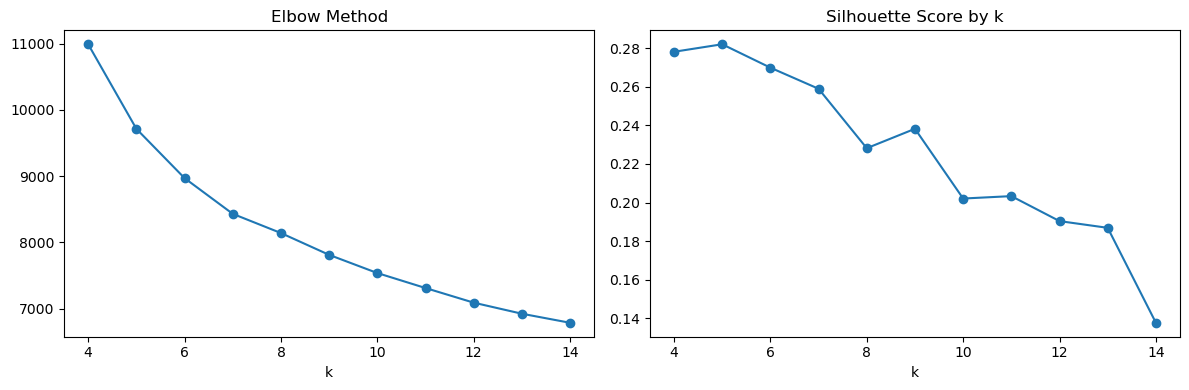

In [61]:
inertias = []
silhouettes = []
k_range = range(4, 15)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca_7)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca_7, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(k_range, inertias, marker='o')
ax1.set_xlabel('k')
ax1.set_title('Elbow Method')
ax2.plot(k_range, silhouettes, marker='o')
ax2.set_xlabel('k')
ax2.set_title('Silhouette Score by k')
plt.tight_layout()
plt.show()

I re ran this after adding a couple more features. Pattern looks similar to before, silhouette score peaks at k=5 (0.282), slightly above k=4, then declines steadily with a small secondary bump at k=9 (0.238). Elbow chart again shows smooth decline with no sharp bend. So the overall structure finding is consistent: broad archetypes support roughly 5 clusters at the top level, same as before.

### Clustering

In [62]:
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
player_stats_filtered['cluster'] = kmeans_final.fit_predict(X_pca_7)

print(player_stats_filtered['cluster'].value_counts().sort_index())

cluster
0    325
1    300
2    271
3    234
4    305
Name: count, dtype: int64


C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


In [63]:
# Validation
cluster_profiles = player_stats_filtered.groupby('cluster')[feature_cols_clustering].mean()
population_mean = player_stats_filtered[feature_cols_clustering].mean()

# Show each cluster's stats as a ratio to the population average -- easier to spot what's distinctive
cluster_profiles_relative = cluster_profiles.div(population_mean, axis=1)
cluster_profiles_relative.round(2)

,goals_p90,shots_p90,total_xg_p90,assists_p90,shot_assists_p90,through_balls_p90,progressive_passes_p90,progressive_carries_p90,pass_completion_pct,dribbles_attempted_p90,...,avg_shot_distance,pressures_p90,tackle_attempts_p90,tackle_pct,aerial_attempts_p90,aerial_pct,interceptions_p90,clearances_p90,miscontrols_p90,dispossessed_p90
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.50,0.79,0.53,0.78,0.98,1.23,0.97,0.54,1.06,0.83,...,1.23,1.33,1.37,1.07,0.82,1.00,1.19,0.71,0.74,0.91
1,0.32,0.35,0.34,0.15,0.21,0.35,0.81,0.16,1.06,0.20,...,0.69,0.61,0.90,0.97,1.14,1.35,1.30,2.34,0.18,0.20
2,1.55,1.68,1.49,2.18,2.01,2.00,1.22,2.11,0.95,2.11,...,1.06,1.14,0.87,1.02,0.65,0.68,0.72,0.24,1.70,1.85
3,2.84,2.01,2.83,1.34,1.08,0.94,0.54,1.31,0.93,1.22,...,0.81,1.01,0.49,1.04,1.81,0.77,0.33,0.31,2.09,1.63
4,0.31,0.48,0.30,0.76,0.84,0.55,1.37,1.09,0.97,0.82,...,1.16,0.89,1.22,0.90,0.75,1.11,1.27,1.19,0.63,0.65


From our clusters it appears that our 5 groups as expected has been broken down more so into position groups. From this I will try two stage clustering on these groups to see if we make some better categorization. I will run the test on the attackers group (cluster 0) to see if this is a viable strategy.

In [64]:
# Isolate cluster 3 now and re run PCA + k-means within the group
strikers_v2 = player_stats_filtered[player_stats_filtered['cluster'] == 3].copy()
print(strikers_v2.shape)
print(strikers_v2['position'].value_counts())

X_strikers_v2_scaled = StandardScaler().fit_transform(strikers_v2[feature_cols_clustering])

pca_strikers_v2 = PCA()
pca_strikers_v2.fit(X_strikers_v2_scaled)
print(np.cumsum(pca_strikers_v2.explained_variance_ratio_)[:6])

(234, 55)
position
Center Forward               109
Left Center Forward           40
Right Center Forward          34
Right Wing                    18
Left Wing                     17
Center Attacking Midfield      8
Right Midfield                 5
Left Midfield                  2
Right Center Midfield          1
Name: count, dtype: int64
[0.1688023  0.3293881  0.44364249 0.52520704 0.59140345 0.64709705]


C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

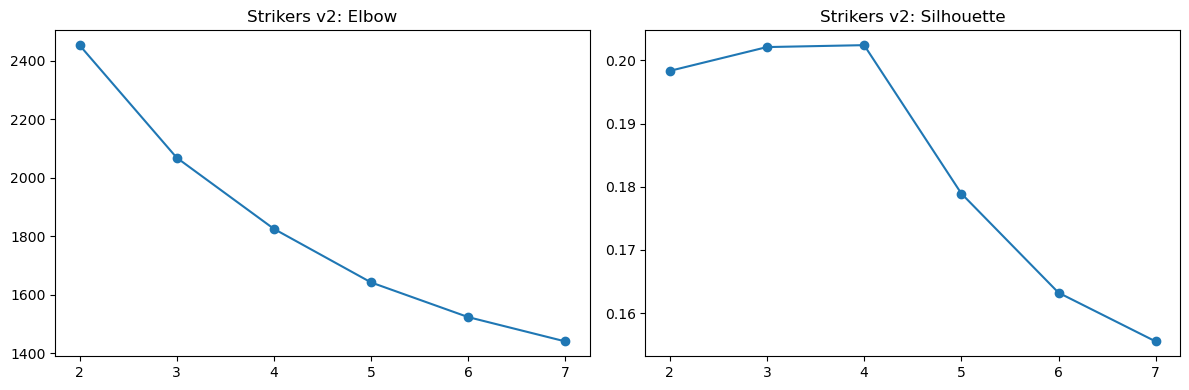

In [65]:
sub_k_range = range(2, 8)
X_strikers_v2_pca = PCA(n_components=5).fit_transform(X_strikers_v2_scaled)

sub_inertias = []
sub_silhouettes = []

for k in sub_k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_strikers_v2_pca)
    sub_inertias.append(km.inertia_)
    sub_silhouettes.append(silhouette_score(X_strikers_v2_pca, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(sub_k_range, sub_inertias, marker='o')
ax1.set_title('Strikers v2: Elbow')
ax2.plot(sub_k_range, sub_silhouettes, marker='o')
ax2.set_title('Strikers v2: Silhouette')
plt.tight_layout()
plt.show()

Silhouette score peaked at k=4 this time and declined steeply after that. k=4 was chosen for this clustering

In [66]:
kmeans_strikers_v2 = KMeans(n_clusters=4, random_state=42, n_init=10)
strikers_v2['sub_cluster'] = kmeans_strikers_v2.fit_predict(X_strikers_v2_pca)

print(strikers_v2['sub_cluster'].value_counts())

striker_v2_profiles = strikers_v2.groupby('sub_cluster')[feature_cols_clustering].mean()
striker_v2_population_mean = strikers_v2[feature_cols_clustering].mean()
striker_v2_profiles_relative = striker_v2_profiles.div(striker_v2_population_mean, axis=1)
striker_v2_profiles_relative.round(2)

sub_cluster
2    111
1     63
0     37
3     23
Name: count, dtype: int64


C:\Users\ausuc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,goals_p90,shots_p90,total_xg_p90,assists_p90,shot_assists_p90,through_balls_p90,progressive_passes_p90,progressive_carries_p90,pass_completion_pct,dribbles_attempted_p90,...,avg_shot_distance,pressures_p90,tackle_attempts_p90,tackle_pct,aerial_attempts_p90,aerial_pct,interceptions_p90,clearances_p90,miscontrols_p90,dispossessed_p90
sub_cluster,,,,,,,,,,,,,,,,,,,,,
0,0.75,0.93,0.73,1.13,1.07,1.33,1.40,1.01,0.96,1.04,...,1.12,1.11,1.49,0.98,1.03,1.22,1.90,1.27,0.95,0.95
1,0.87,0.95,0.87,0.91,0.98,0.82,0.96,1.35,1.05,1.47,...,1.07,1.10,1.13,1.01,0.73,0.77,1.02,0.70,1.14,1.37
2,0.94,0.95,1.01,0.89,0.94,0.84,0.86,0.74,0.98,0.71,...,0.92,0.96,0.84,1.00,1.24,1.07,0.73,1.18,0.98,0.84
3,2.04,1.48,1.75,1.59,1.26,1.74,1.15,1.27,1.04,1.06,...,1.00,0.72,0.62,1.03,0.53,0.95,0.79,0.51,0.77,0.84


In [67]:
# Validation
for i in range(4):
    print(f"\nSub-cluster {i}:")
    print(strikers_v2[strikers_v2['sub_cluster'] == i].sort_values('goals_p90', ascending=False)[['player', 'goals_p90', 'avg_shot_distance', 'progressive_carries_p90', 'through_balls_p90']].head(8))


Sub-cluster 0:
                           player  goals_p90  avg_shot_distance  \
174             Antoine Griezmann   0.633952          15.033696   
43           Adrián López Álvarez   0.442460          11.825000   
1741                   Shane Long   0.406165          12.150794   
1679         Sabin Merino Zuloaga   0.383506          12.418519   
454   Deyverson Brum Silva Acosta   0.361928          12.470833   
1368       Mikel Oyarzabal Ugarte   0.347077          15.243750   
1850                  Troy Deeney   0.339158          16.080851   
163                   Andy Delort   0.332700          17.094406   

      progressive_carries_p90  through_balls_p90  
174                  3.429102           0.316976  
43                   5.862592           0.331845  
1741                 3.289934           0.243699  
1679                 5.215687           0.000000  
454                  2.412851           0.120643  
1368                 5.264004           0.289231  
1850                 2.

After consideration I decided not to move forward with the two stage clustering for the position groups. From the second test we ran with more fetaures on the attacking group we did see meaningful improvements but still got clusters separating the elite from the rest of the pack, however this time we at least slightly categorized the rest of the pack but it is not enough to move forward with.

## Similarity function
Find players that are statistically similar to for teams to find players within the same classes.

In [68]:
# Check if team is in our player stats
print('team' in player_stats_filtered.columns)

False


In [69]:
# Add team back in
player_primary_team = player_minutes.groupby('player')['team'].agg(lambda x: x.value_counts().idxmax()).reset_index()
player_primary_team.columns = ['player', 'team']

player_stats_filtered = player_stats_filtered.merge(player_primary_team, on='player', how='left')

print(player_stats_filtered['team'].isna().sum())
player_stats_filtered[['player', 'team']].head()

0


,player,team
0,Aaron Cresswell,West Ham United
1,Aaron Lennon,Everton
2,Aaron Ramsey,Arsenal
3,Abdelaziz Barrada,Olympique de Marseille
4,Abdelhamid El Kaoutari,Stade de Reims


In [70]:
# Test out the function
find_similar_players('Harry Kane', player_stats_filtered, X_scaled, n=10)

,player,position,team,similarity
616,Jamie Vardy,Left Center Forward,Leicester City,0.906026
530,Gonzalo Gerardo Higuaín,Center Forward,Napoli,0.895705
1183,Romelu Lukaku Menama,Center Forward,Everton,0.894279
177,Benjamin Moukandjo Bilé,Center Forward,Lorient,0.886149
192,Borja González Tomás,Left Center Forward,Eibar,0.884221
286,Daniel Andre Sturridge,Center Forward,Liverpool,0.879741
774,Kelechi Promise Iheanacho,Right Center Forward,Manchester City,0.869685
981,Michy Batshuayi Tunga,Center Forward,Olympique de Marseille,0.869659
664,John Guidetti,Center Forward,Celta Vigo,0.868734
776,Kevin Gameiro,Center Forward,Sevilla,0.866362


## Visualizations

In [71]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print(pca_2d.explained_variance_ratio_.sum())

0.5389545369092738


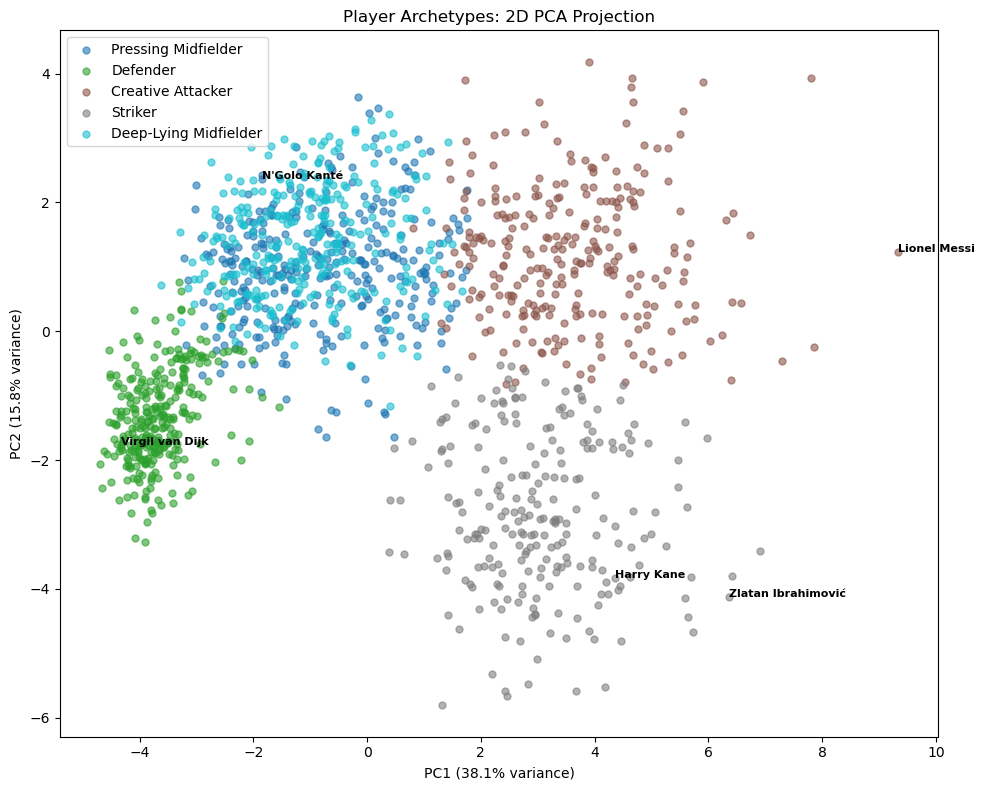

In [72]:
cluster_names = {
    0: 'Pressing Midfielder',
    1: 'Defender',
    2: 'Creative Attacker',
    3: 'Striker',
    4: 'Deep-Lying Midfielder'
}

fig, ax = plt.subplots(figsize=(10, 8))

colors = plt.cm.tab10(np.linspace(0, 1, 5))
for cluster_id in range(5):
    mask = player_stats_filtered['cluster'] == cluster_id
    ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], 
               alpha=0.6, s=25, color=colors[cluster_id], label=cluster_names[cluster_id])

players_to_label = {
    'Harry Kane': 'Harry Kane',
    'Lionel Andrés Messi Cuccittini': 'Lionel Messi',
    'N\'\'Golo Kanté': "N'Golo Kanté",
    'Zlatan Ibrahimović': 'Zlatan Ibrahimović',
    'Virgil van Dijk': 'Virgil van Dijk'
}

for full_name, display_name in players_to_label.items():
    if full_name in player_stats_filtered['player'].values:
        idx = player_stats_filtered.index[player_stats_filtered['player'] == full_name][0]
        idx_pos = player_stats_filtered.index.get_loc(idx)
        ax.annotate(display_name, 
                    (X_pca_2d[idx_pos, 0], X_pca_2d[idx_pos, 1]),
                    fontsize=8, fontweight='bold')
    else:
        print(f"'{full_name}' not found -- check exact spelling in player_stats_filtered")

ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('Player Archetypes: 2D PCA Projection')
ax.legend()
plt.tight_layout()
plt.show()
fig.savefig('../visuals/player_archetype_clusters.png', dpi=150, bbox_inches='tight')

## Saving important data

In [73]:
player_stats_filtered.to_parquet('../data/processed/player_stats_final.parquet')
np.save('../data/processed/player_clustering_X_scaled.npy', X_scaled)
joblib.dump(scaler, '../data/processed/player_clustering_scaler.pkl')
joblib.dump(feature_cols_clustering, '../data/processed/player_clustering_feature_cols.pkl')

['../data/processed/player_clustering_feature_cols.pkl']